# Содержание
1. [Функции](#s1)
2. [Загрузка и предобработка данный](#s2)
   - [2.1 Информация о пользователях](#s2_1)
   - [2.2 Информация о звонках](#s2_2)
   - [2.3 Информация о сообщениях](#s2_3)
   - [2.4 Информация об интернет-сессиях](#s2_4)
   - [2.5 Информация о тарифах](#s2_5)
   - [2.6 Объединение датасетов](#s2_6)
   - [2.7 Расчет переплаты](#s2_7)
3. [Исследовательский анализ данных (EDA)](#s3)
   - [3.1 Анализ пользователей](#s3_1)
   - [3.2 Анализ телефонных разговоров](#s3_2)
   - [3.3 Анализ интернет-трафика](#s3_3)
   - [3.4 Анализ сообщений](#s3_4)
   - [3.5 Анализ доходов по тарифам](#s3_5)
   - [3.6 Вывод](#s3_6)
4. [Проверка гипотез](#s4)
   - [4.1 Гипотеза 1: Средняя выручка пользователей Ultra выше Smart](#s4_1)
   - [4.2 Гипотеза 2: Средняя выручка по Москве отличается от других городов](#s4_2)
5. [Общий вывод](#s5)

# Определение перспективного тарифа для телеком-компании

Клиентам оператора сотовой связи предлагают два тарифных плана: «Smart» и «Ultra». Чтобы скорректировать рекламный бюджет, коммерческий департамент хочет понять, какой тариф приносит больше денег. В вашем распоряжении данные 500 пользователей за 2018 год. Нужно проанализировать поведение клиентов и сделать вывод — какой тариф лучше.

**Примечание:** 

Оператор всегда округляет секунды до минут, а мегабайты — до гигабайт. Каждый звонок округляется отдельно: даже если он длился всего 1 секунду, будет засчитан как 1 минута.

Для веб-трафика отдельные сессии не считаются. Вместо этого общая сумма за месяц округляется в бо́льшую сторону. Если абонент использует 1025 мегабайт в этом месяце, с него возьмут плату за 2 гигабайта.

## Функции

In [1]:
def add_savefig(name):
    # Убираем все символы, кроме букв, цифр, пробелов, дефисов и подчёркиваний
    clean_name = re.sub(r'[^\w\s-]', '', name, flags=re.UNICODE)
    # Заменяем любые последовательности пробелов, дефисов и подчёркиваний на одно подчёркивание
    clean_name = re.sub(r'[\s\-_]+', '_', clean_name).strip('_')    
    filename = f'{clean_name}.png'
    plt.savefig(figures_dir / filename, dpi=150, bbox_inches='tight')

In [2]:
def print_histplot(data, par_x, par_limit_smart, stat='percent', title="Гистограмма"):
    plt.figure(figsize=(8,5))
    sns.histplot(data=data,
                 x=par_x,
                 hue='tariff',
                 hue_order=['smart', 'ultra'],
                 stat=stat,
                 common_norm=False,
                 alpha=0.6,
                 kde=True
                )
    limit_smart = data.loc[data['tariff'] == 'smart', par_limit_smart].unique()[0]
    plt.axvline(limit_smart, color='red', linestyle='--')
    plt.title(f'{title}')
    plt.xlabel('Общая продолжительность')
    plt.grid(True, alpha=0.3)
    add_savefig(f'{par_x} in tariffs')
    plt.show()

In [3]:
def print_barplot(data, par_y, hue='tariff', 
                  estimator='mean', 
                  title="Средняя продолжительность по месяцам", 
                  save_title='Mean duration'):
    plt.figure(figsize = (8,5)) 
    sns.barplot(data=data, 
                x='month',
                y=par_y, 
                #errorbar='sd',
                 estimator=estimator,
                hue=hue)
    plt.title(f'{title}')
    plt.grid(True, alpha=0.3)
    add_savefig(f'{save_title}')
    plt.show()

In [4]:
def extra_charge(df, included, rate, value_col):
    """Переплата сверх пакета, руб."""
    over = (df[value_col] - df[included]).clip(lower=0)
    return (over * df[rate])

In [5]:
def boxplot_print(data, y, title='Boxplot'):
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=data, x='tariff', y=y, palette='Set2', hue='city_group')
    plt.title(title)
    plt.grid(True, alpha=0.3)
    add_savefig(f'{y} boxplot')
    plt.show()

## Загрузка и предобработка данный

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
from scipy import stats as st
import re

In [7]:
# Снимаем ограничение на количество отображаемых столбцов
pd.set_option('display.max_columns', None)

In [8]:
data_dir =  Path('./data')
figures_dir = Path('./images')

### Информация о пользователях

In [9]:
df_users = pd.read_csv(data_dir/'users.csv')

In [10]:
df_users.info()
df_users.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   age         500 non-null    int64 
 2   churn_date  38 non-null     object
 3   city        500 non-null    object
 4   first_name  500 non-null    object
 5   last_name   500 non-null    object
 6   reg_date    500 non-null    object
 7   tariff      500 non-null    object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


,user_id,age,churn_date,city,first_name,last_name,reg_date,tariff
0,1000,52,NaN,Краснодар,Рафаил,Верещагин,2018-05-25,ultra
1,1001,41,NaN,Москва,Иван,Ежов,2018-11-01,smart
2,1002,59,NaN,Стерлитамак,Евгений,Абрамович,2018-06-17,smart
3,1003,23,NaN,Москва,Белла,Белякова,2018-08-17,ultra
4,1004,68,NaN,Новокузнецк,Татьяна,Авдеенко,2018-05-14,ultra


Преобразуем данные в столбце 'reg_date' в формат datetime

In [11]:
df_users['reg_date'] = pd.to_datetime(df_users['reg_date'])

In [12]:
df_users['reg_month'] = df_users['reg_date'].dt.month

Найдем крайние даты. Вместо пропусков с столбце 'churn_date' запишем максимальную дату. Преобразуем в формат datetime

In [13]:
print(f'Дата подключения тарифа {df_users['reg_date'].min().strftime("%Y-%m-%d")} - {df_users['reg_date'].max().strftime("%Y-%m-%d")}')

Дата подключения тарифа 2018-01-01 - 2018-12-31


In [14]:
df_users['churn'] = df_users['churn_date'].notna().astype(int)

In [15]:
df_users['churn_date'] = df_users['churn_date'].fillna(df_users['reg_date'].max())
df_users['churn_date'] = pd.to_datetime(df_users['churn_date'])
df_users['churn_month'] = df_users['churn_date'].dt.month

In [16]:
print('Найдено дубликатов:', df_users.duplicated().sum())

Найдено дубликатов: 0


In [17]:
df_users['lifetime'] = df_users['churn_date'].dt.month - df_users['reg_date'].dt.month + 1

In [18]:
df_users['city_group'] = np.where(df_users['city']=='Москва', 'Moscow', 'Other')

In [19]:
df_users.drop(columns=['first_name', 'last_name', 'churn_date', 'reg_date', 'city'], inplace=True)

In [20]:
df_users.sample(5)

,user_id,age,tariff,reg_month,churn,churn_month,lifetime,city_group
5,1005,67,smart,1,0,12,12,Other
354,1354,56,smart,8,0,12,5,Other
340,1340,50,smart,1,0,12,12,Other
478,1478,75,smart,7,0,12,6,Other
73,1073,63,smart,10,0,12,3,Other


### Информация о звонках

In [21]:
df_calls = pd.read_csv(data_dir/'calls.csv')
df_calls.info()
df_calls.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202607 entries, 0 to 202606
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         202607 non-null  object 
 1   call_date  202607 non-null  object 
 2   duration   202607 non-null  float64
 3   user_id    202607 non-null  int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 6.2+ MB


,id,call_date,duration,user_id
0,1000_0,2018-07-25,0.00,1000
1,1000_1,2018-08-17,0.00,1000
2,1000_2,2018-06-11,2.85,1000
3,1000_3,2018-09-21,13.80,1000
4,1000_4,2018-12-15,5.18,1000


Преобразуем столбец 'call_date' в формат datetime 

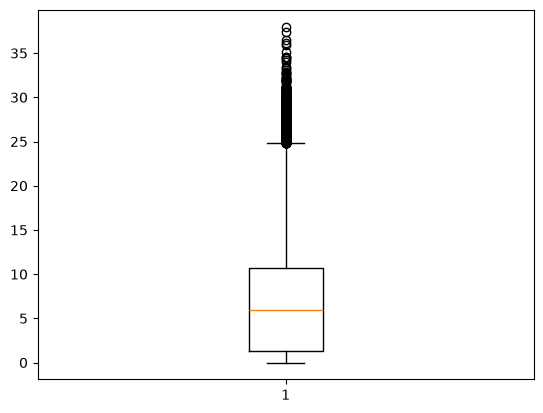

In [22]:
plt.boxplot(df_calls['duration'])
plt.show()

In [23]:
df_calls['call_date'] = pd.to_datetime(df_calls['call_date'])

In [24]:
print(f'Данные за период: {df_calls['call_date'].min().strftime("%Y-%m-%d")} - {df_calls['call_date'].max().strftime("%Y-%m-%d")}')

Данные за период: 2018-01-01 - 2018-12-31


In [25]:
'В таблице содержатся данные о {} пользователях'.format(len(df_calls['user_id'].unique()))

'В таблице содержатся данные о 492 пользователях'

In [26]:
print('Найдено дубликатов:', df_calls.duplicated().sum())

Найдено дубликатов: 0


Создадим новый столбец 'call_month' в таблице calls, куда запишем номер месяца, когда пользователь сделал звонок

In [27]:
df_calls['month'] = df_calls['call_date'].dt.month

Т.к. оператор округляет время разговора до минут в большую сторону, округлим значения до целых.

In [28]:
df_calls['duration'] = np.ceil(df_calls['duration'])

Найдем количество звонков и минут каждого пользователя за месяц, запишем в таблицу 'agg_calls'

In [29]:
agg_calls = df_calls.groupby(['month','user_id']).agg({'duration':'sum','id':'count'}).reset_index()
agg_calls.columns = ['month','user_id','sum_duration','count_calls']
agg_calls.sample(5)

,month,user_id,sum_duration,count_calls
1142,8,1000,408.0,52
2533,11,1310,570.0,82
2618,11,1407,239.0,38
714,6,1200,567.0,83
2493,11,1268,269.0,41


### Информация о сообщениях

In [30]:
df_messages = pd.read_csv(data_dir/'messages.csv')

In [31]:
df_messages.info()
df_messages.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123036 entries, 0 to 123035
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            123036 non-null  object
 1   message_date  123036 non-null  object
 2   user_id       123036 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 2.8+ MB


,id,message_date,user_id
0,1000_0,2018-06-27,1000
1,1000_1,2018-10-08,1000
2,1000_2,2018-08-04,1000
3,1000_3,2018-06-16,1000
4,1000_4,2018-12-05,1000


Преобразуем столбец 'message_date' в формат datetime

In [32]:
df_messages['message_date'] = pd.to_datetime(df_messages['message_date'])

In [33]:
print(f'Данные за период: {df_messages['message_date'].min().strftime("%Y-%m-%d")} - {df_messages['message_date'].max().strftime("%Y-%m-%d")}')

Данные за период: 2018-01-02 - 2018-12-31


In [34]:
'В таблице содержатся данные о {} пользователях'.format(len(df_messages['user_id'].unique()))

'В таблице содержатся данные о 426 пользователях'

In [35]:
print('Найдено дубликатов:', df_messages.duplicated().sum())

Найдено дубликатов: 0


In [36]:
df_messages['month'] = df_messages['message_date'].dt.month

Найдем сумму сообщений каждого пользователя за месяц, данные сохраним в таблице 'sum_sms'

In [37]:
agg_sms = df_messages.groupby(['month','user_id']).agg({'id':'count'}).reset_index()
agg_sms.columns = ['month','user_id','sum_sms']
agg_sms.sample(5)

,month,user_id,sum_sms
2695,12,1474,105
1840,10,1381,43
2102,11,1238,30
1343,9,1149,99
1673,10,1148,12


### Информация об интернет-сессиях

In [38]:
df_internet = pd.read_csv(data_dir/'internet.csv', index_col=0)
df_internet.info()
df_internet.head()

<class 'pandas.core.frame.DataFrame'>
Index: 149396 entries, 0 to 149395
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            149396 non-null  object 
 1   mb_used       149396 non-null  float64
 2   session_date  149396 non-null  object 
 3   user_id       149396 non-null  int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 5.7+ MB


,id,mb_used,session_date,user_id
0,1000_0,112.95,2018-11-25,1000
1,1000_1,1052.81,2018-09-07,1000
2,1000_2,1197.26,2018-06-25,1000
3,1000_3,550.27,2018-08-22,1000
4,1000_4,302.56,2018-09-24,1000


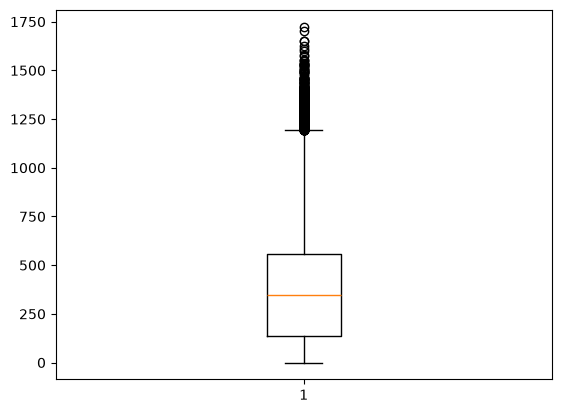

In [39]:
plt.boxplot(df_internet['mb_used'])
plt.show()

Преобразуем столбец 'session_date' в формат datetime

In [40]:
df_internet['session_date'] = pd.to_datetime(df_internet['session_date'])

In [41]:
print(f'Данные за период: {df_internet['session_date'].min().strftime("%Y-%m-%d")} - {df_internet['session_date'].max().strftime("%Y-%m-%d")}')

Данные за период: 2018-01-01 - 2018-12-31


In [42]:
'В таблице содержатся данные о {} пользователях'.format(len(df_internet['user_id'].value_counts()))

'В таблице содержатся данные о 497 пользователях'

In [43]:
df_internet['month'] = df_internet['session_date'].dt.month

Найдем объем интернет-трафика в Мб каждого пользователя за месяц

In [44]:
agg_internet = df_internet.groupby(['month','user_id']).agg({'mb_used':'sum'}).reset_index()
agg_internet.columns = ['month','user_id','sum_mb']

In [45]:
agg_internet['sum_gb'] = np.ceil(agg_internet['sum_mb']/1024) 

In [46]:
agg_internet.sample(5)

,month,user_id,sum_mb,sum_gb
2984,12,1269,17969.07,18.0
2214,10,1422,8448.75,9.0
3160,12,1455,12696.63,13.0
640,6,1056,11265.41,12.0
2109,10,1301,19640.11,20.0


### Информация о тарифах

In [47]:
df_tariffs = pd.read_csv(data_dir/'tariffs.csv')
df_tariffs.info()
df_tariffs.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   messages_included      2 non-null      int64 
 1   mb_per_month_included  2 non-null      int64 
 2   minutes_included       2 non-null      int64 
 3   rub_monthly_fee        2 non-null      int64 
 4   rub_per_gb             2 non-null      int64 
 5   rub_per_message        2 non-null      int64 
 6   rub_per_minute         2 non-null      int64 
 7   tariff_name            2 non-null      object
dtypes: int64(7), object(1)
memory usage: 260.0+ bytes


,messages_included,mb_per_month_included,minutes_included,rub_monthly_fee,rub_per_gb,rub_per_message,rub_per_minute,tariff_name
0,50,15360,500,550,200,3,3,smart
1,1000,30720,3000,1950,150,1,1,ultra


In [48]:
df_tariffs['gb_included'] = df_tariffs['mb_per_month_included'] / 1024

In [49]:
df_tariffs

,messages_included,mb_per_month_included,minutes_included,rub_monthly_fee,rub_per_gb,rub_per_message,rub_per_minute,tariff_name,gb_included
0,50,15360,500,550,200,3,3,smart,15.0
1,1000,30720,3000,1950,150,1,1,ultra,30.0


### Объединение датасетов

Объединим информацию о пользователях с данными о звонках, смс и интернет.

In [50]:
users_history = pd.merge(agg_calls, agg_sms, on=['user_id', 'month'], how='outer')

In [51]:
users_history = pd.merge(users_history, agg_internet, on=['user_id', 'month'], how='outer')

In [52]:
users_history = pd.merge(users_history, df_users, on=['user_id'], how='outer')

In [53]:
users_history.shape

(3216, 14)

In [54]:
users_history = users_history.fillna(0)

In [55]:
users_history['month'] = users_history['month'].replace(0,1)

In [56]:
users_history = pd.merge(users_history, df_tariffs, left_on='tariff', right_on='tariff_name', how='left')

In [57]:
users_history.drop(columns=['tariff_name'], inplace=True)

### Расчет переплаты

Найдем переплату в рублях за звонки, смс и интернет.

In [58]:
users_history['extra_duration'] = extra_charge(users_history,
                                               'minutes_included', 'rub_per_minute', 'sum_duration')

users_history['extra_sms'] = extra_charge(users_history, 
                                          'messages_included', 'rub_per_message', 'sum_sms')

users_history['extra_gb'] = extra_charge(users_history, 
                                         'gb_included', 'rub_per_gb', 'sum_gb')

users_history['extra_charges'] = (users_history['extra_duration']
                                  + users_history['extra_sms']
                                  + users_history['extra_gb'])
users_history['revenue'] = users_history['rub_monthly_fee'] + users_history['extra_charges']

In [59]:
users_history.sample(5)

,month,user_id,sum_duration,count_calls,sum_sms,sum_mb,sum_gb,age,tariff,reg_month,churn,churn_month,lifetime,city_group,messages_included,mb_per_month_included,minutes_included,rub_monthly_fee,rub_per_gb,rub_per_message,rub_per_minute,gb_included,extra_duration,extra_sms,extra_gb,extra_charges,revenue
2486,11.0,1389,263.0,37.0,1.0,15763.61,16.0,29,smart,7,0,12,6,Moscow,50,15360,500,550,200,3,3,15.0,0.0,0.0,200.0,200.0,750.0
1143,8.0,1178,404.0,58.0,30.0,18080.19,18.0,56,smart,5,0,12,8,Moscow,50,15360,500,550,200,3,3,15.0,0.0,0.0,600.0,600.0,1150.0
1578,12.0,1248,808.0,109.0,0.0,17917.43,18.0,51,smart,5,0,12,8,Moscow,50,15360,500,550,200,3,3,15.0,924.0,0.0,600.0,1524.0,2074.0
2182,5.0,1344,762.0,117.0,124.0,22818.54,23.0,60,ultra,4,0,12,9,Other,1000,30720,3000,1950,150,1,1,30.0,0.0,0.0,0.0,0.0,1950.0
2629,10.0,1409,655.0,99.0,43.0,16436.25,17.0,42,smart,3,0,12,10,Other,50,15360,500,550,200,3,3,15.0,465.0,0.0,400.0,865.0,1415.0


## Исследовательский анализ данных (EDA)

### Анализ пользователей

In [60]:
df_users['tariff'].value_counts()

tariff
smart    351
ultra    149
Name: count, dtype: int64

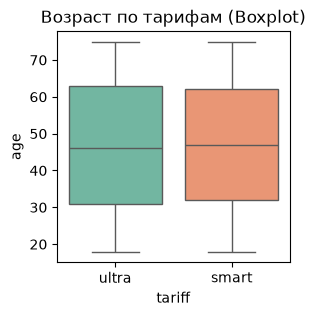

In [61]:
plt.figure(figsize=(3, 3))
sns.boxplot(data=df_users, x='tariff', y='age', hue='tariff', palette='Set2', legend=False)
plt.title('Возраст по тарифам (Boxplot)')
plt.show()

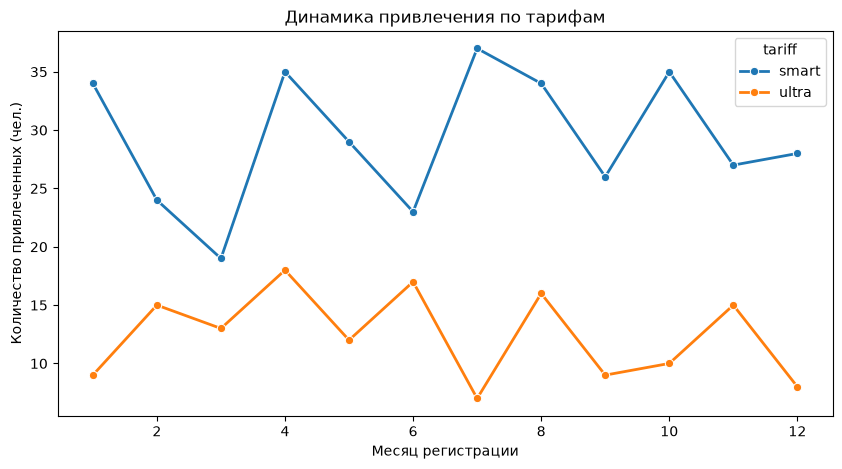

In [62]:
df_reg = df_users.groupby(['reg_month', 'tariff']).size().reset_index(name='count')

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_reg, x='reg_month', y='count', hue='tariff', marker='o', linewidth=2)
plt.ylabel('Количество привлеченных (чел.)')
plt.xlabel('Месяц регистрации')
plt.title('Динамика привлечения по тарифам')
add_savefig('reg_new_client')
plt.show()

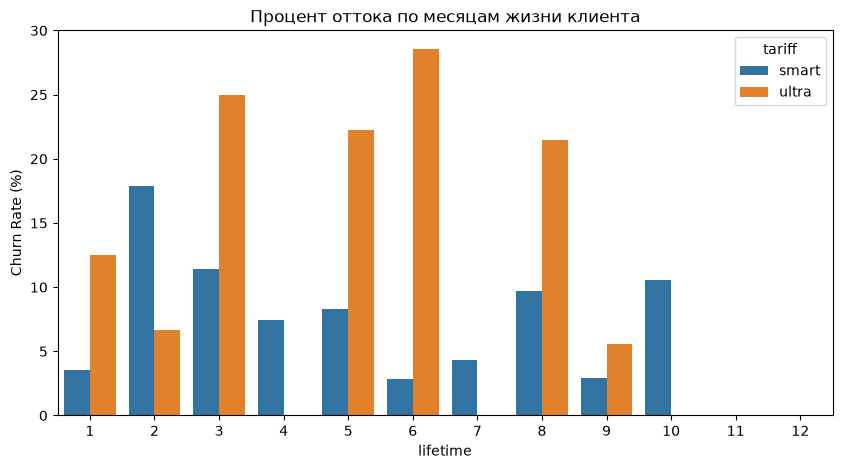

In [63]:
total_users = df_users.groupby(['lifetime', 'tariff']).size().reset_index(name='total')
churned = df_users[df_users['churn'] == 1].groupby(['lifetime', 'tariff']).size().reset_index(name='churned')
churn_rate = pd.merge(total_users, churned, on=['lifetime', 'tariff'], how='left').fillna(0)
churn_rate['churn_pct'] = (churn_rate['churned'] / churn_rate['total']) * 100

plt.figure(figsize=(10,5))
sns.barplot(data=churn_rate, x='lifetime', y='churn_pct', hue='tariff')
plt.ylabel('Churn Rate (%)')
plt.title('Процент оттока по месяцам жизни клиента')
add_savefig('Churn Rate')
plt.show()

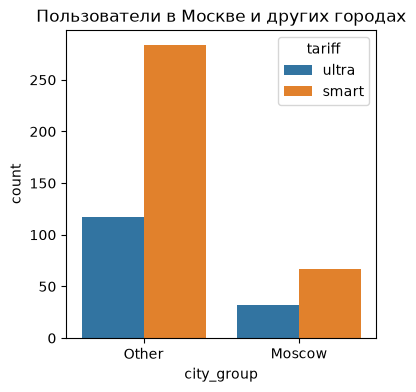

In [64]:
plt.figure(figsize=(4,4))
sns.countplot(data=df_users, x='city_group', hue='tariff')
plt.title('Пользователи в Москве и других городах')
plt.show()

### Анализ телефонных разговоров

In [65]:
zero_share = (
    users_history
    .assign(no_calls=users_history['sum_duration'] == 0)
    .groupby('tariff')['no_calls']
    .mean()
    .mul(100)
    .round(2)
)
print(f'Доля «спящих» пользователей \n', zero_share)

Доля «спящих» пользователей 
 tariff
smart    0.40
ultra    3.96
Name: no_calls, dtype: float64


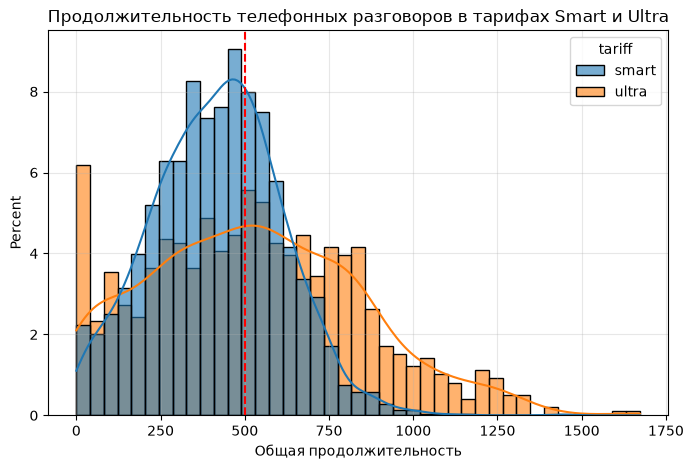

In [66]:
title = "Продолжительность телефонных разговоров в тарифах Smart и Ultra"
print_histplot(users_history,'sum_duration', 'minutes_included', stat='percent', title=title)

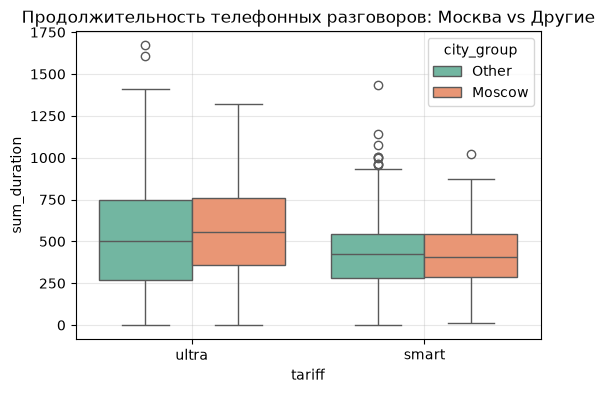

In [67]:
title = 'Продолжительность телефонных разговоров: Москва vs Другие'
boxplot_print(users_history, 'sum_duration', title=title)

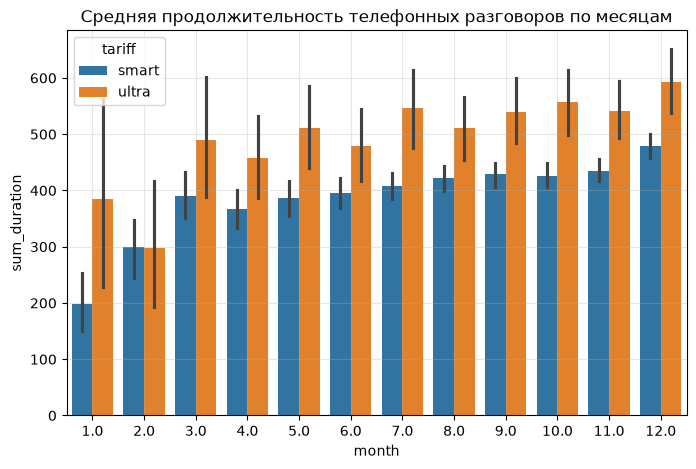

In [68]:
title="Средняя продолжительность телефонных разговоров по месяцам"
save_title='average duration calls by month'
print_barplot(users_history, 'sum_duration', title=title, save_title=save_title)

In [69]:
users_history.groupby(['tariff','city_group'])['sum_duration'].describe()

count        mean         std   min    25%    50%     75%  \
tariff city_group                                                               
smart  Moscow       386.0  417.481865  177.402663  12.0  290.0  408.0  544.00   
       Other       1844.0  417.803145  193.147092   0.0  281.0  426.5  545.25   
ultra  Moscow       225.0  557.791111  303.785251   0.0  356.0  553.0  762.00   
       Other        761.0  516.716163  321.533690   0.0  272.0  500.0  746.00   

                      max  
tariff city_group          
smart  Moscow      1022.0  
       Other       1435.0  
ultra  Moscow      1321.0  
       Other       1673.0

In [70]:
smart = users_history[users_history['tariff'] == 'smart']
total = len(smart)
over_500 = (smart['sum_duration'] > 500).sum()
print(f"Доля пользователей превышающих лимит 500 мин: {over_500 / total * 100:.1f}%")

Доля пользователей превышающих лимит 500 мин: 33.8%


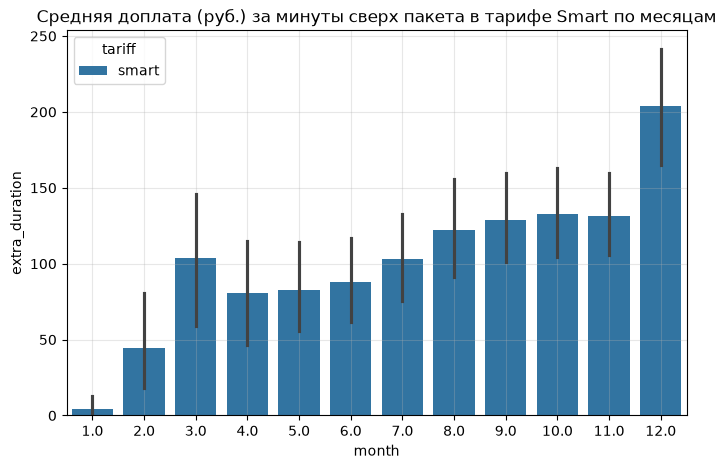

In [71]:
title="Средняя доплата (руб.) за минуты сверх пакета в тарифе Smart по месяцам"
print_barplot(smart, 'extra_duration', title=title)

In [72]:
print("Эмпирические 95-е перцентили:")
np.ceil(users_history.groupby('tariff')['sum_duration'].quantile(0.95))

Эмпирические 95-е перцентили:


tariff
smart     727.0
ultra    1089.0
Name: sum_duration, dtype: float64

### Анализ интернет-трафика

In [73]:
zero_share = (
    users_history
    .assign(no_gb=users_history['sum_gb'] == 0)
    .groupby('tariff')['no_gb']
    .mean()
    .mul(100)
    .round(2)
)
print(f'Доля «спящих» пользователей \n', zero_share)

Доля «спящих» пользователей 
 tariff
smart    0.13
ultra    1.22
Name: no_gb, dtype: float64


Посмотрим гистограмму интернет-трафика по каждому тарифу. Красной пунктирной линией отметим лимит в пакете Smart.

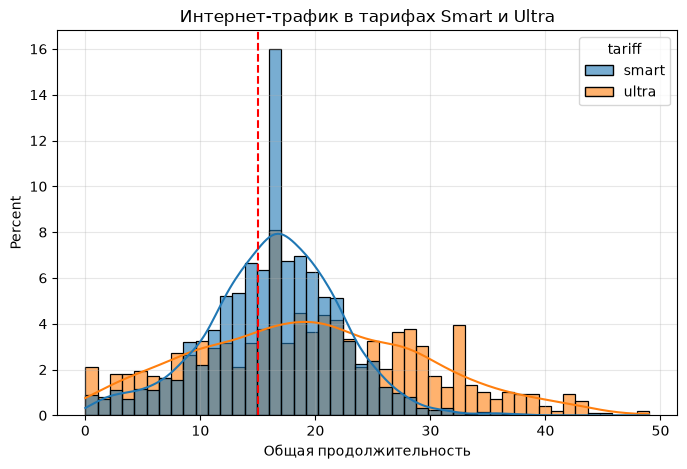

In [74]:
title = "Интернет-трафик в тарифах Smart и Ultra"
print_histplot(users_history,'sum_gb', 'gb_included', stat='percent', title=title)

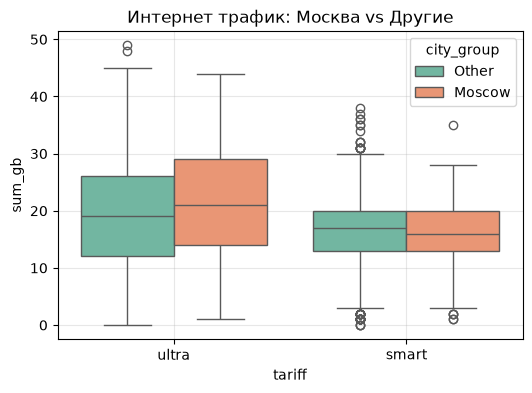

In [75]:
title = 'Интернет трафик: Москва vs Другие'
boxplot_print(users_history, 'sum_gb', title=title)

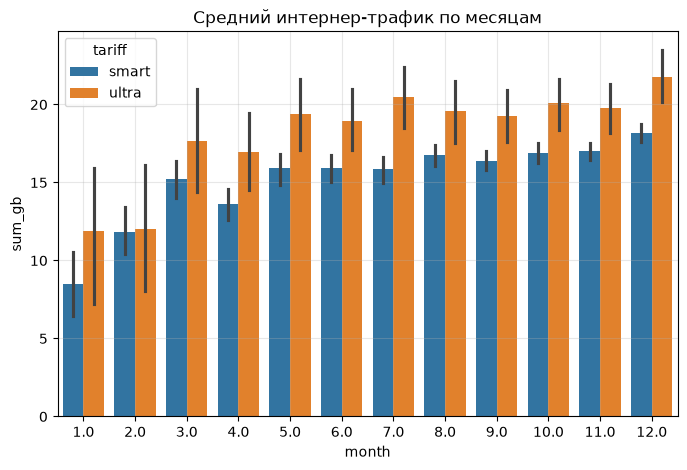

In [76]:
title="Средний интернер-трафик по месяцам"
save_title="Average internet by month"
print_barplot(users_history, 'sum_gb', title=title, save_title=save_title)

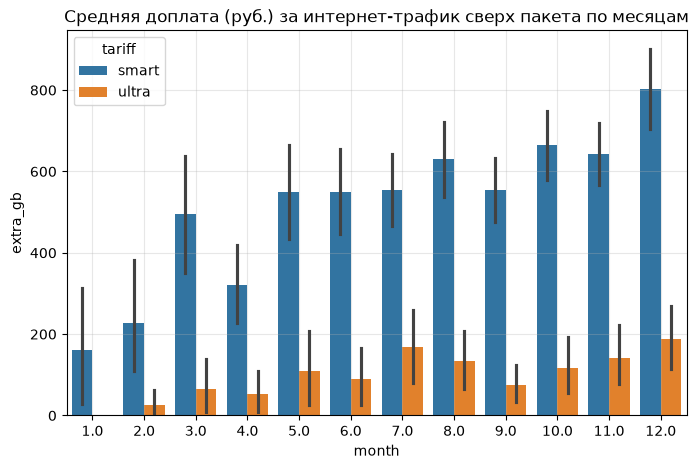

In [77]:
title="Средняя доплата (руб.) за интернет-трафик сверх пакета по месяцам"
save_title="Average surcharge (RUB) for internet"
print_barplot(users_history, 'extra_gb', title=title, save_title=save_title)

In [78]:
smart = users_history[users_history['tariff'] == 'smart']
total = len(smart)
over_15 = (smart['sum_gb'] > 15).sum()
print(f"Превышают лимит 15 Гб в тарифе Smart: {over_15 / total * 100:.1f}%")

Превышают лимит 15 Гб в тарифе Smart: 58.5%


In [79]:
ultra = users_history[users_history['tariff'] == 'ultra']
total = len(ultra)
over_30 = (ultra['sum_gb'] > 30).sum()
print(f"Превышают лимит 30 Гб в тарифе Ultra: {over_30 / total * 100:.1f}%")

Превышают лимит 30 Гб в тарифе Ultra: 13.6%


In [80]:
users_history.groupby(['tariff','city_group'])['sum_gb'].describe()

count       mean       std  min   25%   50%   75%   max
tariff city_group                                                          
smart  Moscow       386.0  16.160622  5.491444  1.0  13.0  16.0  20.0  35.0
       Other       1844.0  16.355206  5.810927  0.0  13.0  17.0  20.0  38.0
ultra  Moscow       225.0  21.293333  9.520804  1.0  14.0  21.0  29.0  44.0
       Other        761.0  18.936925  9.910718  0.0  12.0  19.0  26.0  49.0

In [81]:
print("Эмпирические 95-е перцентили:")
np.ceil(users_history.groupby('tariff')['sum_gb'].quantile(0.95))

Эмпирические 95-е перцентили:


tariff
smart    25.0
ultra    37.0
Name: sum_gb, dtype: float64

### Анализ сообщений

In [82]:
users_history.head(2)

,month,user_id,sum_duration,count_calls,sum_sms,sum_mb,sum_gb,age,tariff,reg_month,churn,churn_month,lifetime,city_group,messages_included,mb_per_month_included,minutes_included,rub_monthly_fee,rub_per_gb,rub_per_message,rub_per_minute,gb_included,extra_duration,extra_sms,extra_gb,extra_charges,revenue
0,5.0,1000,159.0,22.0,22.0,2253.49,3.0,52,ultra,5,0,12,8,Other,1000,30720,3000,1950,150,1,1,30.0,0.0,0.0,0.0,0.0,1950.0
1,6.0,1000,172.0,43.0,60.0,23233.77,23.0,52,ultra,5,0,12,8,Other,1000,30720,3000,1950,150,1,1,30.0,0.0,0.0,0.0,0.0,1950.0


In [83]:
zero_share = (
    users_history
    .assign(no_sms=users_history['sum_sms'] == 0)
    .groupby('tariff')['no_sms']
    .mean()
    .mul(100)
    .round(2)    
)
print(f'Доля «спящих» пользователей \n', zero_share)

Доля «спящих» пользователей 
 tariff
smart    13.81
ultra    19.37
Name: no_sms, dtype: float64


In [84]:
#fact_sms = users_history[users_history['sum_sms'] > 0].copy()

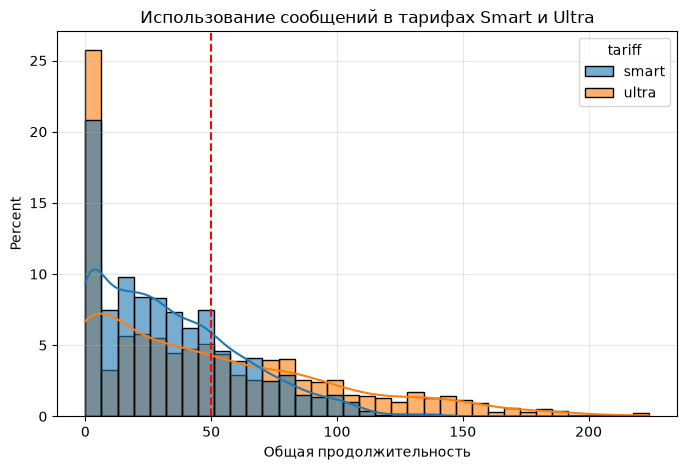

In [85]:
title = "Использование сообщений в тарифах Smart и Ultra"
print_histplot(users_history,'sum_sms', 'messages_included', stat='percent', title=title)

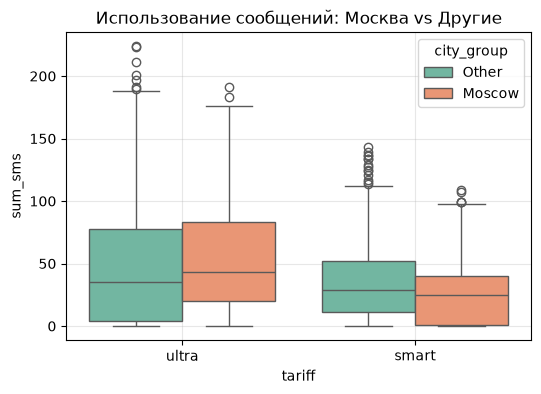

In [86]:
title = 'Использование сообщений: Москва vs Другие'
boxplot_print(users_history, 'sum_sms', title=title)

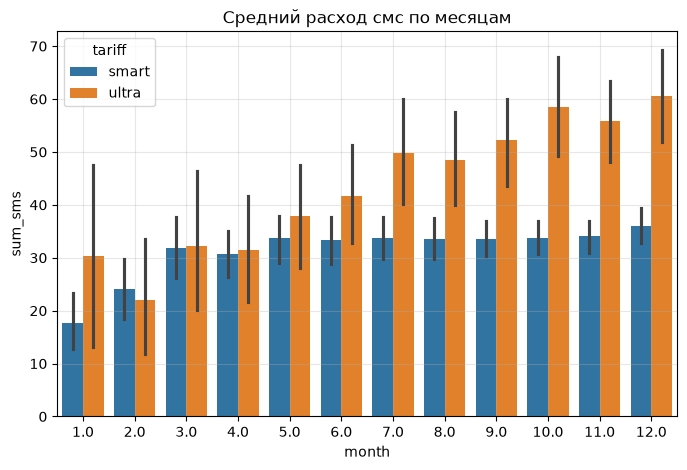

In [87]:
title="Средний расход смс по месяцам"
save_title="Average SMS by month"
print_barplot(users_history, 'sum_sms', title=title, save_title=save_title)

In [88]:
smart = users_history[users_history['tariff'] == 'smart']
total = len(smart)
over_50 = (smart['sum_sms'] > 50).sum()
print(f"Превышают лимит 50 sms в тарифе Smart: {over_50 / total * 100:.1f}%")

Превышают лимит 50 sms в тарифе Smart: 25.3%


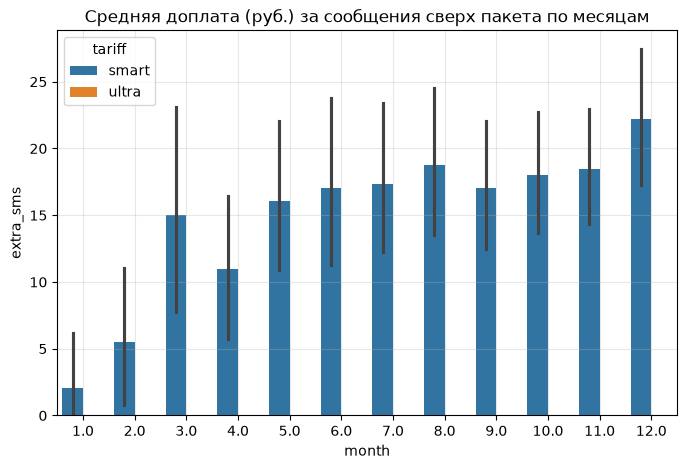

In [89]:
title="Средняя доплата (руб.) за сообщения сверх пакета по месяцам"
save_title="Average surcharge (RUB) for messages"
print_barplot(users_history, 'extra_sms', title=title, save_title=save_title)

In [90]:
print("Эмпирические 95-е перцентили:")
np.ceil(users_history.groupby('tariff')['sum_sms'].quantile(0.95))

Эмпирические 95-е перцентили:


tariff
smart     88.0
ultra    145.0
Name: sum_sms, dtype: float64

In [91]:
users_history.groupby(['tariff','city_group'])['sum_sms'].describe()

count       mean        std  min   25%   50%   75%    max
tariff city_group                                                            
smart  Moscow       386.0  27.772021  25.959806  0.0   1.0  25.0  40.0  109.0
       Other       1844.0  34.540672  28.550951  0.0  11.0  29.0  52.0  143.0
ultra  Moscow       225.0  55.213333  46.090350  0.0  20.0  43.0  83.0  191.0
       Other        761.0  47.568988  48.192878  0.0   4.0  35.0  78.0  224.0

### Анализ доходов по тарифам

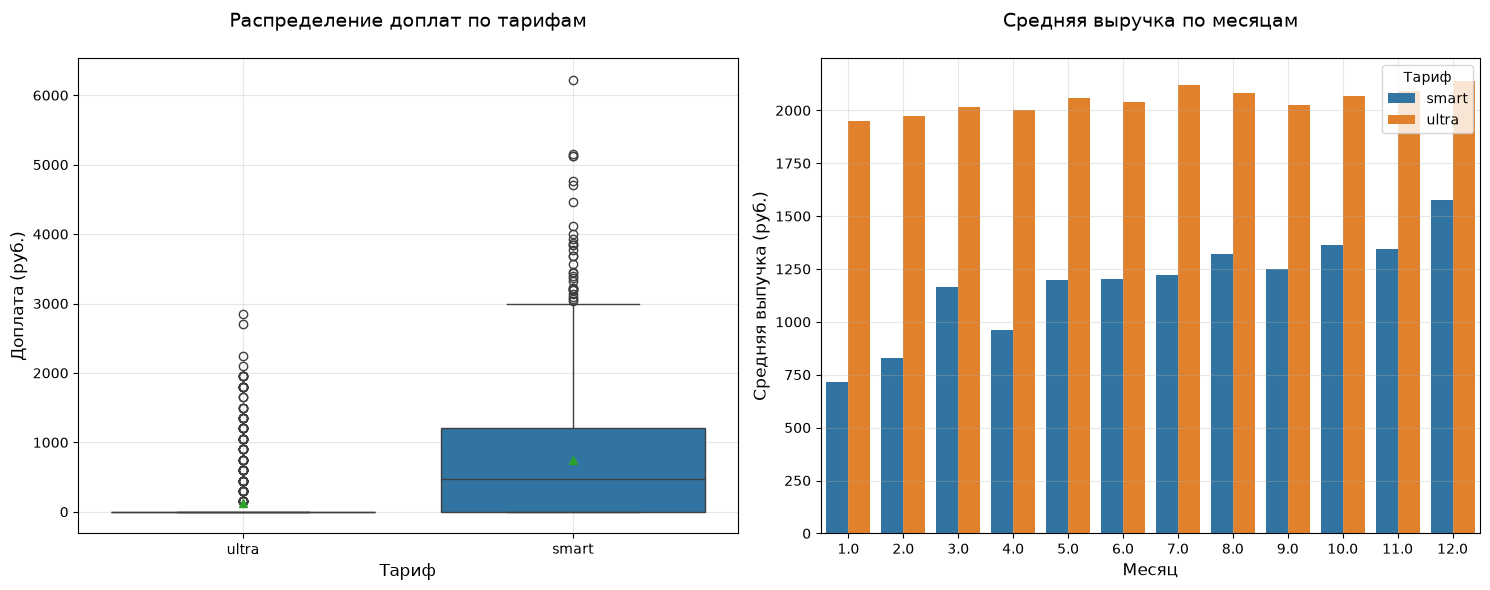

In [92]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

sns.boxplot(
    data=users_history, 
    x='tariff', 
    y='extra_charges',
    showmeans=True,
    ax=axes[0] 
)
axes[0].set_title("Распределение доплат по тарифам\n", fontsize=14)
axes[0].set_xlabel("Тариф", fontsize=12)
axes[0].set_ylabel("Доплата (руб.)", fontsize=12)
axes[0].grid(True, alpha=0.3)

sns.barplot(
    data=users_history, 
    x='month', 
    y='revenue', 
    hue='tariff', 
    errorbar=None, 
    ax=axes[1] 
)
axes[1].set_title("Средняя выручка по месяцам\n", fontsize=14)
axes[1].set_xlabel("Месяц", fontsize=12)
axes[1].set_ylabel("Средняя выпучка (руб.)", fontsize=12)
axes[1].legend(title="Тариф")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
add_savefig('extra_charges by month')
plt.show()

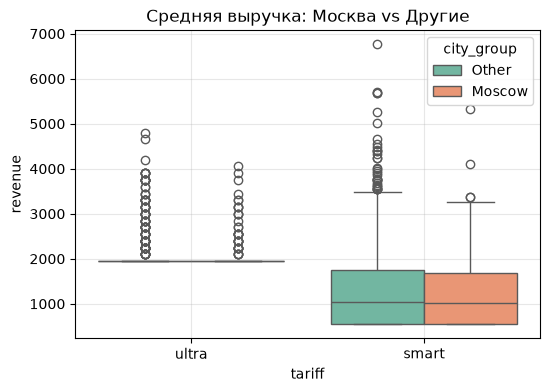

In [93]:
title = 'Средняя выручка: Москва vs Другие'
boxplot_print(users_history, 'revenue', title=title)

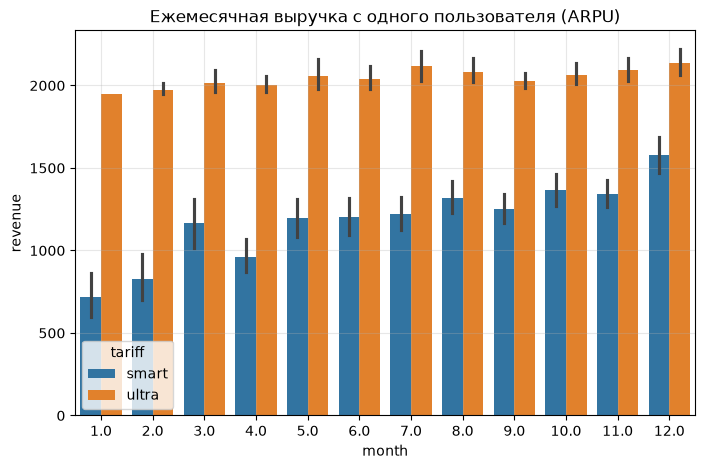

In [94]:
title="Ежемесячная выручка с одного пользователя (ARPU)"
save_title="ARPU_tariff"
print_barplot(users_history, 'revenue', title=title, save_title=save_title)

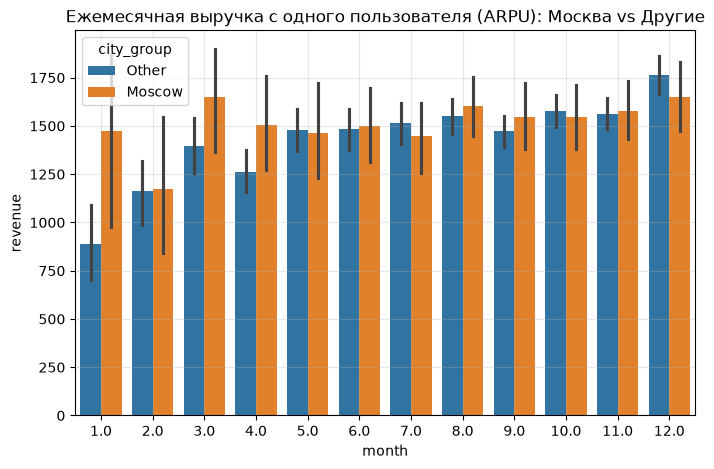

In [95]:
title="Ежемесячная выручка с одного пользователя (ARPU): Москва vs Другие"
save_title="ARPU_city_group"
print_barplot(users_history, 'revenue',  hue='city_group', title=title, save_title=save_title)

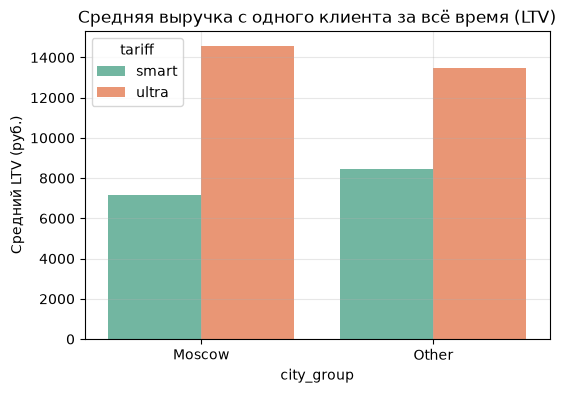

In [96]:
ltv_by_users = users_history.groupby(['user_id', 'tariff', 'city_group'])['revenue'].sum().reset_index(name='ltv')
# Считаем средний LTV по тарифам
ltv_by_tariff = ltv_by_users.groupby(['tariff', 'city_group'])['ltv'].mean().reset_index()

plt.figure(figsize=(6,4))
sns.barplot(data=ltv_by_tariff,
           x='city_group',
           y='ltv',
           hue='tariff',
           palette='Set2',
           legend=True 
           )
plt.title('Средняя выручка с одного клиента за всё время (LTV)')
plt.ylabel('Средний LTV (руб.)')
plt.grid(True, alpha=0.3)
add_savefig('LTV by city_group')
plt.show()

In [97]:
print(f'\nСредняя выручка: Москва vs Другие')
ltv_by_users.groupby('city_group')['ltv'].mean().reset_index(name='ltv_region').set_index('city_group')


Средняя выручка: Москва vs Другие


,ltv_region
city_group,
Moscow,9545.878788
Other,9905.009975


In [98]:
print(f'\nГодовой доход по тарифам')
users_history.groupby('tariff')['revenue'].sum().reset_index(name='sum_revenue').set_index('tariff')


Годовой доход по тарифам


,sum_revenue
tariff,
smart,2875901.0
ultra,2041050.0


In [99]:
users_history.groupby(['tariff','city_group'])[['extra_charges', 'revenue']].describe().round(2)

extra_charges                                            \
                          count    mean     std  min   25%    50%     75%   
tariff city_group                                                           
smart  Moscow             386.0  689.36  753.45  0.0  0.00  457.5  1124.5   
       Other             1844.0  750.17  831.13  0.0  2.25  488.5  1200.0   
ultra  Moscow             225.0  124.00  350.10  0.0  0.00    0.0     0.0   
       Other              761.0  118.86  383.55  0.0  0.00    0.0     0.0   

                          revenue                                            \
                      max   count     mean     std     min      25%     50%   
tariff city_group                                                             
smart  Moscow      4771.0   386.0  1239.36  753.45   550.0   550.00  1007.5   
       Other       6220.0  1844.0  1300.17  831.13   550.0   552.25  1038.5   
ultra  Moscow      2100.0   225.0  2074.00  350.10  1950.0  1950.00  1950.0   
       Other       2850.0   761.0  2068.86  383.55  1950.0  1950.00  1950.0   

                                   
                      75%     max  
tariff city_group                  
smart  Moscow      1674.5  5321.0  
       Other       1750.0  6770.0  
ultra  Moscow      1950.0  4050.0  
       Other       1950.0  4800.0

### Вывод

На основе данных о пользователях тарифов Smart (351 абонент) и Ultra (149 абонентов) за 2018 год, проживающих в Москве и других регионах установлено, что возрастных отличий нет. Тарифами одинаково пользуются люди от 18 до 75 лет. Однако поведение пользователей двух тарифов существенно различается:

Пользователи Smart в среднем разговаривают 420 минут в месяц, пользователи Ultra — 525 минут. Гистограмма продолжительности телефонных разговоров показывает, что оба распределения смещены влево с длинным правым «хвостом» — то есть есть небольшая группа пользователей с очень длительными разговорами. При этом пользователи Ultra не выходят за пределы пакета (3000 минут), тогда как по Smart 33.9% пользователей доплачивают за минуты сверх пакета. График средней доплаты за минуты по Smart демонстрирует рост с заметным пиком в декабре — по-видимому, сказывается сезонный рост активности (праздники, отпуска). Так же установлено, что 3.96% абонентов Ultra не используют минуты разговора, что в 10 раз выше, чем Smart — 0.40%. Вероятно, тариф берут из-за интернета.

Пользователи тарифа Smart и Ultra в среднем используют примерно одинаковое количество Гб в месяц - 16 и 19 Гб соответственно. При этом превышают лимит 15 Гб в тарифе Smart: 58.6%, лимит 30 Гб в тарифе Ultra: 13.8%. 

Так же наблюдается использование сообщений сверх лимита в тарифе Smart. График средней доплаты за сообщения сверх пакета имеет тенденцию роста от месяца к месяцу. На гистограмме видно, что существует не большое количество абонентов, часто отправляющих сообщения, при этом 29.3% в тарифе Smart превышают лимит 50 sms.

Анализ доплат сверх пакета выявил принципиально разную структуру потребления. В тарифе Smart доплаты носят массовый характер: медиана составляет ~450-500 руб., что означает, что более половины пользователей регулярно выходят за пределы пакета. Доплата достигает 6000 руб. в месяц. 
В тарифе Ultra ситуация иная: медианная доплата равна нулю, однако среднее значение положительное. Это свидетельствует о том, что доплаты по Ultra формируются не за счет массового потребления, а за счет единичных клиентов (~2000-3000 руб всерх пакета). График средней доплаты сверх пакета по месяцам имеет тенденцию к росту в тарифе Smart и волнообразную линию в тарифе Ultra. Рост тарифа Ultra сдерживается критически высоким уровнем оттока. В отличие от Smart, где отток стабилен, Ultra теряет более 20% клиентов на 3-м, 5-м, 6-м и 8-м месяцах жизни. Пик потерь приходится на 6-й месяц, когда уходит почти треть (28%) пользователей. Это нивелирует приток новых клиентов.

Анализ данных показал, что компания в 2018 году заработала на тарифе Smart почти на миллион рублей больше, чем на тарифе Ultra. Однако, не все так однозначно. В предоставленной выборке пользователей тарифа Smart в 2,3 раза больше, чем пользователей тарифа Ultra. Возможно, именно этим обусловлена такая прибыль по тарифам. Также анализ показал, что средняя выручка по Москве сопоставима с выручкой в других городах, не смотря на меньшее количество пользователей в Москве. Чтобы это опровергнуть необходимо проверить гипотезы:

- средняя выручка пользователей тарифов Ultra выше Smart;
- средняя выручка пользователей из Москвы отличается от выручки пользователей из других регионов. 


## 4. Проверка гипотез

### Гипотеза 1: Средняя выручка пользователей Ultra выше Smart

Проверим гипотезу "Средняя выручка пользователей тарифов Ultra выше Smart".

 - Нулевая гипотеза H0: **μUltra = μSmart** (Средняя выручка по тарифу Ultra равна средней выручке тарифа Smart). 
 

 - Альтернативная гипотеза H₁: **μUltra > μSmart** (Средняя выручка по тарифу  Ultra больше средней выручки тарифа Smart). 

In [100]:
users_history.groupby('tariff')[['revenue']].agg(['var']).round().T

,tariff,smart,ultra
revenue,var,669731.0,141388.0


In [101]:
group_ultra = users_history[users_history['tariff']=='ultra']['revenue']
group_smart = users_history[users_history['tariff']=='smart']['revenue']

In [102]:
print(f'Размеры выборок пользователей Ultra и Smart соответственно: {len(group_ultra)} / {len(group_smart)}')

Размеры выборок пользователей Ultra и Smart соответственно: 986 / 2230


In [103]:
alpha = .05 # уровень статистической значимости

results = st.ttest_ind(
    group_ultra,
    group_smart,
    equal_var=False,
    alternative='greater'
)

print('t-статистика:', results.statistic)
print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print("Отвергаем H0. Cредняя выручка Ultra значимо больше Smart")
else:
    print("Не отвергаем H0")

t-статистика: 37.047170235598124
p-значение: 9.635056972101132e-251
Отвергаем H0. Cредняя выручка Ultra значимо больше Smart


**Вывод**

Значение p-value говорит о том, что вероятность получить такое или большее различие случайно нулевая. Следовательно мы вправе отклонить нулевую гипотезу в пользу альтернативной: Cредняя выручка Ultra значимо больше Smart.

### Гипотеза 2: Средняя выручка по Москве отличается от других городов

In [104]:
users_history.groupby('city_group')[['revenue']].agg(['var']).round().T

,city_group,Moscow,Other
revenue,var,565636.0,654070.0


In [105]:
group_moscow = users_history[users_history['city_group'] == 'Moscow']['revenue']
group_other = users_history[users_history['city_group'] == 'Other']['revenue']

In [106]:
print(f'Размеры выборок пользователей из Москвы и других городов соответственно: {len(group_moscow)} / {len(group_other)}')

Размеры выборок пользователей из Москвы и других городов соответственно: 611 / 2605


Проверим гипотезу "Средняя выручка от пользователей из Москвы отличается от других городов".

 - Нулевая гипотеза H₀: **μMoscow = μOther** (Средняя выручка Москвы равна выручке других городов). 

 - Альтернативная гипотеза H₁: **μMoscow ≠ μOther** (Средняя выручка Москвы отличается от выручки других городов). 


In [107]:
alpha = .05 # уровень статистической значимости

results = st.ttest_ind(
    group_moscow,
    group_other,
    equal_var=False
)

print('t-статистика:', results.statistic)
print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print("Отвергаем H0. Средняя выручка Москвы отличается от выручки других городов")
else:
    print("Не отвергаем H0")

t-статистика: 0.6409677091149435
p-значение: 0.5216952110000279
Не отвергаем H0


**Вывод**

Значение p-value говорит о том, что вероятность получить такое или большее различие случайно почти 52%, хотя средний доход от пользователей в Москве отличается от дохода по другим регионам. Это явно слишком большая вероятность, чтобы делать вывод о том, что средние выручки различны.

## Общий вывод

На основе проведенного анализа поведения пользователей тарифов Smart и Ultra за 2018 год, я пришла к следующим выводам:

1) Выручки по тарифам Ultra и Smart различны:
   - Статистически подтверждено, что средняя выручка с пользователя тарифа Ultra значимо выше
   - Несмотря на меньшее количество пользователей в выборке, тариф демонстрирует лучшую монетизацию. В среднем клиенты Ultra приносят в 1.6 раз больше выручки, чем Smart
   - Smart — это база, он обеспечивает стабильный денежный поток.     
2) Тариф Smart имеет структурные проблемы:
   - В 58.5% случаях не достаточно 15 Гб бесплатного трафика.
   - Доля пользователей превышающих лимит 500 мин 33.8%, особенно в декабре.
   - Наблюдается постоянный отток клиентов. Максимальный на 2-м месяце жизни - 18%
5) Тариф Ultra лучше соответствует реальным потребностям:
   - 30 ГБ интернета покрывает потребности большинства пользователей
   - 3000 минут разговора никогда не исчерпываются
   - 1000 сообщений существенно превышает реальные нужды
   - Большой отток клиентов, особенно через 6 месяцев (28%)
6) География не влияет на выручку
   - Пользователи из Москвы и других регионов приносят сравнимую выручку
  
**Рекомендации для коммерческого департамента:**

1) Сохранить или увеличить долю бюджета на привлечение Ultra, при условии, что стоимость привлечения (CAC) остается ниже LTV. Одновременно с этим перенаправить часть маркетингового бюджета на удержание клиентов Ultra на 4–6 месяце жизни, чтобы максимизировать их LTV за счет снижения оттока».

2) Ввести «перенос остатков» (Roll-over). Если пользователь Ultra не истратил 20 ГБ в этом месяце — пусть перейдут на следующий. Это визуально снимет боль от «сгоревших» денег и повысит лояльность.

3) Сделать доплаты в Smart выгодными (пакетами), предлагать «Автопакет» дополнительных Гб или минут по сниженной цене.

**Ожидаемый результат:**

Перераспределение рекламного бюджета в пользу тарифа Ultra и корректировка тарифных планов позволят:
   - Увеличить средний чек
   - Улучшить пользовательский опыт
   - Снизить отток клиентов из-за несоответствия тарифов реальным потребностям

**Финальная рекомендация:** Пользователи тарифа Ultra демонстрируют значительно более высокий показатель пожизненной ценности (LTV). В среднем один клиент Ultra приносит в 1.6 раза больше выручки, чем клиент Smart (16 800 руб. против 10 200 руб.). Это означает, что, несмотря на высокий уровень оттока Ultra (пик на 6-м месяце), затраты на привлечение этого сегмента оправданы.